# 21｜从 MSE 到 Ridge 与 LASSO：回归与正则化

## 用上半张图，预测下半张图有多亮

继续使用上一课的 digits 数据。给出一张数字的上半部分（前 32 个像素），预测下半部分 32 个像素的平均灰度。目标是一个连续数值，因此这是**回归**任务；它不需要数字标签。这个人为构造的任务帮助我们观察损失与正则化，不能替代手写数字分类。

同一数据划分下，我们比较常数基线、普通线性回归、Ridge 和 LASSO。先用训练集拟合，再依据验证 MSE 选择一个方案，最后报告测试 MSE。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error
style()

## 1 输入、目标与留出数据

每个样本的上半图 $x_i\in\mathbb R^{32}$；下半图平均灰度 $y_i$ 是一个标量。像素原始范围为 0 到 16。划分时参考数字类别分层，使三份集合的数字组成相近；类别标签不进入模型输入和回归目标。训练集以外的数据不参与标准化或参数拟合。

In [3]:
digits = load_digits()
X = digits.images[:, :4, :].reshape(len(digits.images), -1).astype(float)
y = digits.images[:, 4:, :].mean(axis=(1, 2))
labels = digits.target
X_train, X_rest, y_train, y_rest, label_train, label_rest = train_test_split(
    X, y, labels, test_size=.4, stratify=labels, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=.5, stratify=label_rest, random_state=42)
print('X train/val/test:', X_train.shape, X_val.shape, X_test.shape)
print('example target (mean bottom-half brightness):', round(y_train[0], 3))

X train/val/test: (1078, 32) (359, 32) (360, 32)
example target (mean bottom-half brightness): 4.375


### 练习 reg01：算平均亮度

若下半图的四个示例像素为 `[0, 4, 8, 12]`，平均值是多少？存入 `ex_brightness`。

In [4]:
ex_brightness = None

In [5]:
# 填写上一格后，运行检查。
check('mean brightness', ex_brightness, 6.)

待填写：mean brightness


<details>
<summary>提示</summary>

求和再除以像素个数。

</details>

<details>
<summary>参考答案</summary>

```python
ex_brightness = np.mean([0, 4, 8, 12])
```

</details>

## 2 用 MSE 衡量偏差

线性预测为 $\hat y_i = x_i^T w+b$，其中 $w$ 为 32 个特征权重，$b$ 为偏置。均方误差（MSE）为

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^n(\hat y_i-y_i)^2.$$

例如真实值 1、2，预测 2、4，误差分别为 1、2，MSE 为 $(1^2+2^2)/2=2.5$。平方使较大的误差贡献更大；MSE 的单位是目标单位的平方。

对某个预测值求导，$\partial\mathrm{MSE}/\partial\hat y_i=2(\hat y_i-y_i)/n$。若预测偏高，梯度为正，沿负梯度方向调整会降低预测值。用链式法则可继续得到对 $w$ 的导数。

### 练习 reg02：计算 MSE

真实值 `[1, 2]`，预测 `[2, 4]`。计算 MSE，存入 `ex_mse`。

In [6]:
ex_mse = None

In [7]:
# 填写上一格后，运行检查。
check('MSE', ex_mse, 2.5)

待填写：MSE


<details>
<summary>提示</summary>

先逐项相减并平方，再取平均。

</details>

<details>
<summary>参考答案</summary>

```python
ex_mse = np.mean((np.array([2, 4])-np.array([1, 2]))**2)
```

</details>

### 练习 reg03：计算预测梯度

上题中第二个预测值是 4、目标是 2，$n=2$。求 MSE 对该预测值的导数并存入 `ex_derivative`。

In [8]:
ex_derivative = None

In [9]:
# 填写上一格后，运行检查。
check('MSE derivative', ex_derivative, 2.)

待填写：MSE derivative


<details>
<summary>提示</summary>

代入 $2(\hat y_i-y_i)/n$。

</details>

<details>
<summary>参考答案</summary>

```python
ex_derivative = 2*(4-2)/2
```

</details>

## 3 为什么要约束系数？

当特征相关或数据有限时，许多不同的权重组合可能产生相近预测。正则化在拟合误差之外增加对系数大小的代价，使模型对系数的使用受到约束：

- **Ridge** 增加 L2 项 $\sum_j w_j^2$，通常使系数向零收缩；
- **LASSO** 增加 L1 项 $\sum_j|w_j|$，部分系数可能恰好变为零。

两者均通常不惩罚截距。由于不同特征尺度会改变惩罚的作用，这里对每种模型使用只在训练集拟合的标准化。注意实现中的损失归一化：scikit-learn Ridge 的目标是残差平方和加 `alpha * ||w||²`；Lasso 使用 `1/(2n)` 倍残差平方和加 `alpha * ||w||₁`，所以两种模型的相同 `alpha` 不能直接理解为相同强度。

### 练习 reg04：区分 L1 和 L2

对于权重 `[3, -4]`，分别计算 L1（绝对值之和）和 L2 平方（平方之和）。保存为 `ex_l1` 与 `ex_l2_squared`。

In [10]:
ex_l1 = None
ex_l2_squared = None

In [11]:
# 填写上一格后，运行检查。
check('L1', ex_l1, 7)
check('L2 squared', ex_l2_squared, 25)

待填写：L1
待填写：L2 squared


<details>
<summary>提示</summary>

绝对值分别是 3、4；平方分别是 9、16。

</details>

<details>
<summary>参考答案</summary>

```python
ex_l1 = abs(3) + abs(-4)
ex_l2_squared = 3**2 + (-4)**2
```

</details>

## 4 使用验证集比较配置

常数基线只预测训练集目标的平均值。线性模型使用相同的划分和标准化；下表给出预先指定的一组参数。先看验证 MSE，选择最小值，再统一查看对应的测试结果。

In [12]:
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge alpha=10': make_pipeline(StandardScaler(), Ridge(alpha=10.)),
    'Ridge alpha=100': make_pipeline(StandardScaler(), Ridge(alpha=100.)),
    'LASSO alpha=0.02': make_pipeline(StandardScaler(), Lasso(alpha=.02, max_iter=10000)),
    'LASSO alpha=0.1': make_pipeline(StandardScaler(), Lasso(alpha=.1, max_iter=10000)),
}
validation_mse = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    validation_mse[name] = mean_squared_error(y_val, model.predict(X_val))
    print(f'{name:22s} validation MSE = {validation_mse[name]:.4f}')
selected_name = min(validation_mse, key=validation_mse.get)
selected = models[selected_name]
print('selected on validation:', selected_name)

Mean baseline          validation MSE = 1.0433
Linear regression      validation MSE = 0.6907
Ridge alpha=10         validation MSE = 0.6855
Ridge alpha=100        validation MSE = 0.6699
LASSO alpha=0.02       validation MSE = 0.6716
LASSO alpha=0.1        validation MSE = 0.7236
selected on validation: Ridge alpha=100


## 5 看系数和预测误差

横轴是输入像素编号；每条线表示一个模型的 32 个系数。由于训练集标准化后每个坐标的尺度相近，这些系数可以在同一图中比较。线条接近零说明对应像素的线性权重较小；它本身不能证明该像素在因果意义上不重要。

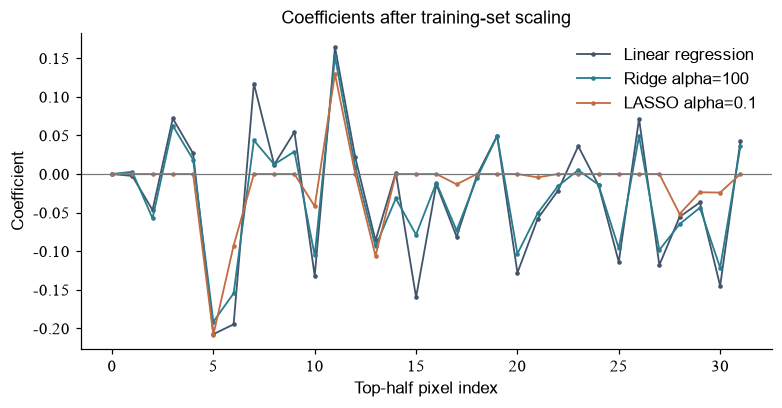

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
for name, color in [('Linear regression', '#42556c'), ('Ridge alpha=100', '#287d8e'), ('LASSO alpha=0.1', '#c36c43')]:
    coef = models[name][-1].coef_
    ax.plot(np.arange(32), coef, marker='.', markersize=4, linewidth=1.2, color=color, label=name)
ax.axhline(0, color='#777777', linewidth=.8)
ax.set(xlabel='Top-half pixel index', ylabel='Coefficient', title='Coefficients after training-set scaling')
ax.legend(frameon=False)
show(fig)

selected test MSE: 0.6546


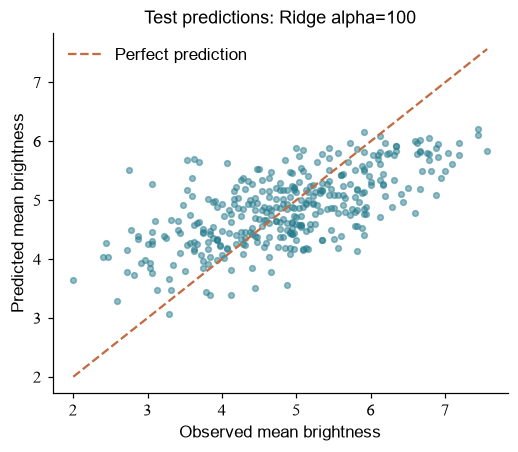

In [14]:
test_pred = selected.predict(X_test)
print('selected test MSE:', round(mean_squared_error(y_test, test_pred), 4))
fig, ax = plt.subplots(figsize=(4.6, 4), layout='constrained')
ax.scatter(y_test, test_pred, s=14, alpha=.5, color='#287d8e')
lo = min(y_test.min(), test_pred.min()); hi = max(y_test.max(), test_pred.max())
ax.plot([lo, hi], [lo, hi], color='#c36c43', linestyle='--', label='Perfect prediction')
ax.set(xlabel='Observed mean brightness', ylabel='Predicted mean brightness', title=f'Test predictions: {selected_name}')
ax.legend(frameon=False)
show(fig)

### 练习 reg05：读一条残差

若真实值为 2、预测值为 2.5，按“预测减真实”定义残差，存入 `ex_residual`。

In [15]:
ex_residual = None

In [16]:
# 填写上一格后，运行检查。
check('residual', ex_residual, .5)

待填写：residual


<details>
<summary>提示</summary>

用预测值减去真实值。

</details>

<details>
<summary>参考答案</summary>

```python
ex_residual = 2.5 - 2
```

</details>

## 6 带着问题继续

1. 固定划分，只改变 Ridge 的 `alpha`，记录验证 MSE 与系数的 L2 范数；解释误差与收缩如何变化。
2. 比较 LASSO 不同 `alpha` 下的非零系数数量，并检查验证误差。不要根据测试集反复调整 `alpha`。
3. 记录测试集残差最大的几个样本。查看上半图：哪些图像给模型留下的信息不足？

阅读 [scikit-learn 线性模型](https://scikit-learn.org/stable/modules/linear_model.html)和[数据泄漏](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)。说明训练均值、模型参数、验证选择和测试结果分别在哪里产生。